# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Giustacchini 2017's CML malignant manifold is **non-branching**: the developmental signatures collapse
onto a **single dominant axis** rather than a hub radiating into cross-repressing arms. Gast and pSom
**co-vary** (smoothed r ≈ +0.70) and both oppose Crest (Gast↔Crest r ≈ −0.93, pSom↔Crest r ≈ −0.80) — a
single **(Gast/pSom)→Crest** gradient with Crest a single terminal tip. A PPT *tree* over this compact
2k-cell cloud finds no real branch point; the correct topology is a **principal curve** (ElPiGraph,
non-branching by construction) fit on the **joint** embedding — never a re-embedding, which would fabricate
folds in an elongated compartment. Rooted at the Gast/pSom-high developmental origin, pseudotime flows to
the neural-crest terminus. Deliverables: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
#--------------------------------------------------
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their **original joint embedding** (no re-embedding). Score the three embryonic
signatures against the shared **union** control pool and graph-smooth them to read geography rather than
per-cell SmartSeq2 dropout.

In [2]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 2040 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 2.31
Gast: 70/81 genes present
pSom: 79/98 genes present
Crest: 97/104 genes present
raw module means (honest readout): {'Gast': 0.0157, 'pSom': 0.0131, 'Crest': -0.0152}


### Scope decision — whole manifold, verified cell-cycle-free axis
The manifold is one low-cycling body (≈16% cycling, no separable proliferative lobe), so — unlike the
Kürten/Lin manifolds — there is no cycling compartment to scope out. We keep the **whole manifold** but
verify the axis is developmental, not proliferative: the developmental gene sets are essentially
**cell-cycle-free** (Gast 0/81, Crest 0/104 overlap with S+G2M), the Gast/pSom↔Crest anti-correlation holds
within the whole manifold, and (below) pseudotime is checked against a cycling score.

In [3]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
print('cycling fraction: %.3f (single low-cycling body)' % adata.obs['cycling'].astype(str).map({'True':1,'False':0}).mean())
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.70
  Crest_sm vs Gast_sm: r = -0.93
  Crest_sm vs pSom_sm: r = -0.80
cycling fraction: 0.158 (single low-cycling body)


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1 (minimum
distance between graph-non-adjacent nodes, in median-edge-length units) certifies the curve does not fold
back on itself. `epg_mu=100` is strong bending regularisation. Fold-freeness and the **2-tip / 0-fork**
topology are stable across Nodes = 15/20/30 — confirming the non-branching read.

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med_edge, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.97
curve N=30: 2 tips, 0 forks | self-approach 2.96
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(gastrulation/somitogenesis is **early**, neural crest is **late**). Pseudotime then flows to the
neural-crest terminus. We also verify pseudotime is **not** proliferation-driven (rho vs cycling reported).

In [5]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
hi = sub.obs['Crest_sm'] >= sub.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s,g2m))
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (Crest terminus modestly more cycling; '
      'axis is developmental — modules are cell-cycle-free and geography survives partialling out cycling, see 01)')

tip 0: Gast=+0.0415 pSom=+0.0086 Crest=-0.0452
tip 2: Gast=-0.0397 pSom=-0.0116 Crest=+0.0588
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.570 p=9.3e-176
  pSom_sm: rho=-0.007 p=7.4e-01
  Crest_sm: rho=+0.597 p=3.6e-197
Neural-crest-high decile mean pseudotime = 0.90 (terminal if ~1)
caveat: pseudotime vs cycling score rho = +0.67 (Crest terminus modestly more cycling; axis is developmental — modules are cell-cycle-free and geography survives partialling out cycling, see 01)


### House orientation (re-used from 01, verified against pseudotime)
The house orientation (rigid rotation to horizontal, Gast/pSom origin on the left) was derived once in 01
and stored as `X_umap_lin`. Every UMAP deliverable across 01–04 re-uses these coordinates. Here we
**verify** it now that pseudotime exists: correlation of the stored x-axis with pseudotime must be strongly
positive (origin on the left).

In [6]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)
Pseudotime on the house linear layout, `figsize=(3.5,1.5)`, `size=30` — matching every other panel.

saved manifold.h5ad + manifold.pdf


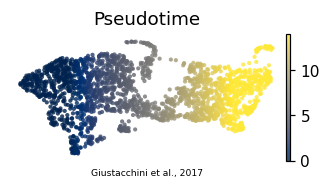

In [7]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Giustacchini et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')